# Среднее и форма распределения

Сравним три искусственные выборки с одинаковым средним: компактную, двугорбую и асимметричную. Покажем, какую информацию добавляет raincloud plot, и настроим горизонтальный вариант.

In [1]:
import sys
from pathlib import Path

# Примеры работают из корня проекта и из папки examples.
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Откройте ноутбук из папки проекта RainView.")
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from rainview import format_summary, raincloudplot

%matplotlib inline

In [2]:
data = pd.read_csv(ROOT / "data" / "distributions.csv")
data.groupby("distribution", sort=False)["value"].agg(["count", "mean", "std"])

,count,mean,std
distribution,,,
Компактное,120,1.552758e-17,0.709337
Два пика,120,1.406282e-16,2.414985
Правый хвост,120,6.291264e-17,1.269785


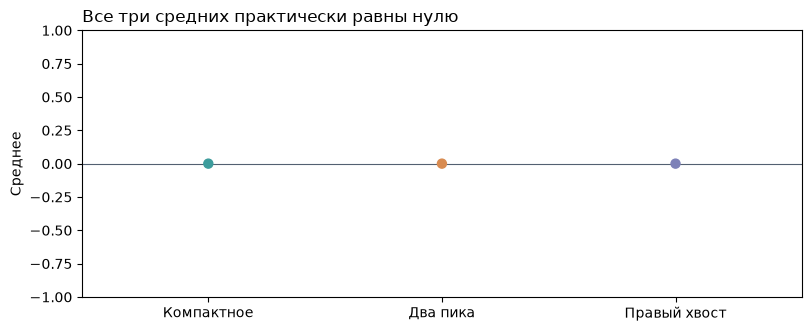

In [3]:
means = data.groupby("distribution", sort=False)["value"].mean()
bar_fig, bar_ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
bar_ax.bar(means.index, means.values, color=["#3D9C9C", "#D88B51", "#7D81B8"])
bar_ax.scatter(
    range(len(means)), means.values, color=["#3D9C9C", "#D88B51", "#7D81B8"], s=42, zorder=3
)
bar_ax.set_ylim(-1, 1)
bar_ax.axhline(0, color="#536071", linewidth=0.8)
bar_ax.set_title("Все три средних практически равны нулю", loc="left")
bar_ax.set_ylabel("Среднее")
plt.show()

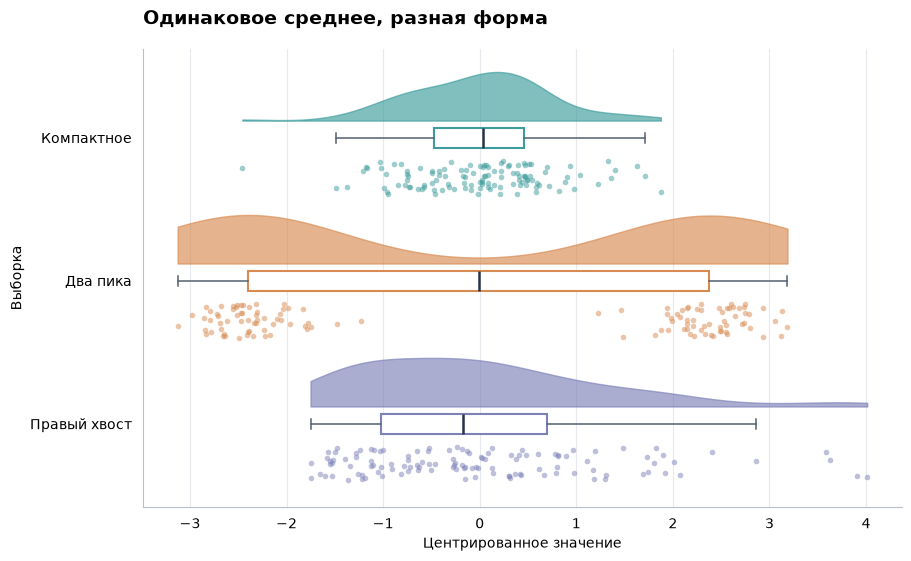

In [4]:
colors = {"Компактное": "#3D9C9C", "Два пика": "#D88B51", "Правый хвост": "#7D81B8"}
fig, ax, summary = raincloudplot(
    data,
    value="value",
    group="distribution",
    orientation="horizontal",
    palette=colors,
    order=["Компактное", "Два пика", "Правый хвост"],
    title="Одинаковое среднее, разная форма",
    x_label="Центрированное значение",
    y_label="Выборка",
    figsize=(9, 5.5),
    point_alpha=0.5,
    point_size=16,
)
plt.show()

Ширина half-violin нормирована отдельно для каждой группы: она показывает относительную форму, а не число участников. Размер каждой выборки можно проверить в сводке. При горизонтальной ориентации x_label обозначает подпись числовой оси X, y_label — категориальной оси Y.

In [5]:
print(format_summary(summary))

Всего строк: 360; использовано: 360; исключено: 0.
Из них без метки группы: 0.
Компактное: n=120, среднее=1.819e-17, медиана=0.03447, std=0.7093, min=-2.457, max=1.875, исключено в группе=0.
Два пика: n=120, среднее=1.179e-16, медиана=-0.006282, std=2.415, min=-3.128, max=3.186, исключено в группе=0.
Правый хвост: n=120, среднее=5.938e-17, медиана=-0.1733, std=1.27, min=-1.751, max=4.011, исключено в группе=0.


## Управление слоями и обычный Matplotlib

Можно отключить точки, сохранить boxplot и доработать возвращённые оси. Выбросы останутся видны как маркеры boxplot.

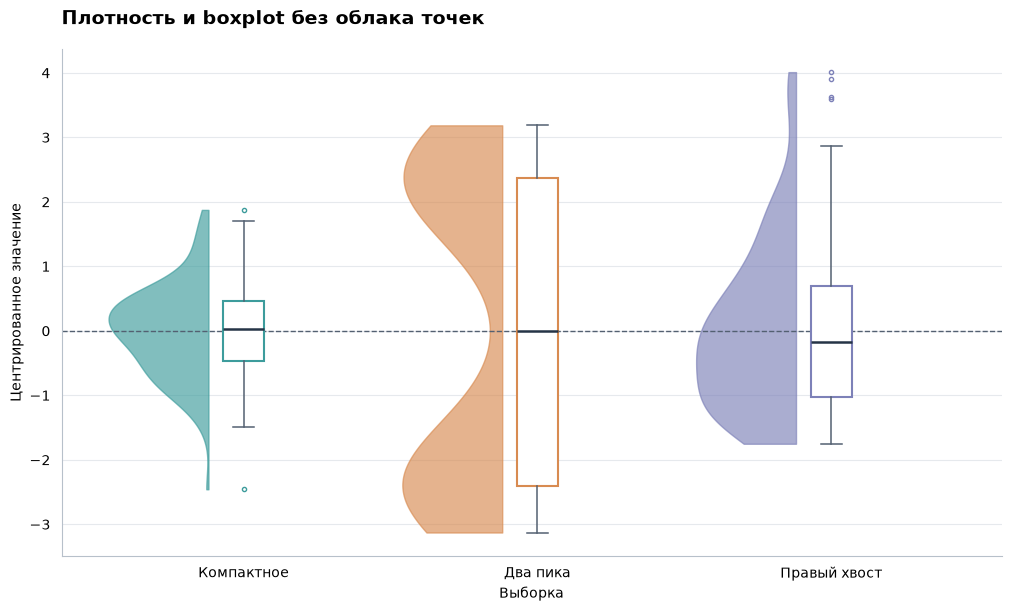

In [6]:
fig_clean, ax_clean, _ = raincloudplot(
    data,
    "value",
    "distribution",
    palette=colors,
    show_points=False,
    title="Плотность и boxplot без облака точек",
    x_label="Выборка",
    y_label="Центрированное значение",
)
ax_clean.axhline(0, linestyle="--", linewidth=1, color="#536071")
plt.show()

Плотность рассчитана Gaussian KDE по правилу Скотта и ограничена диапазоном наблюдений. Сглаживание может скрывать детали формы; сопоставляйте его с точками и объёмом выборки.